

```
# This is formatted as code
```

[link text](https://)#  Lim Convolutional Autoencoder for MVTec AD Anomaly Detection

**Google Colab / PyTorch notebook**

This notebook builds and trains a convolutional autoencoder (CAE) from scratch for **one MVTec AD category** (default: `hazelnut`).

### Method
- Train using **normal training images only** (`train/good`).
- Hold out some normal training images for validation.
- Reconstruct test images using the trained CAE.
- Calculate pixel-wise reconstruction errors and an image-level anomaly score.
- Set the image-level threshold using only normal validation images.
- Evaluate on the test set using image AUROC, pixel AUROC, and classification metrics.

> This is a reconstruction-based baseline. A CAE does not guarantee that every defect will have a high reconstruction error. The threshold is calibrated from normal validation data; the test set is not used to select it.

### Dataset layout expected

After obtaining and extracting MVTec AD, the category folder should look like:

```text
mvtec_anomaly_detection/
└── hazelnut/
    ├── train/
    │   └── good/
    ├── test/
    │   ├── good/
    │   ├── crack/
    │   ├── cut/
    │   └── ...
    └── ground_truth/
        ├── crack/
        ├── cut/
        └── ...
```

Change `CATEGORY` and `DATA_ROOT` below if using another category or folder location.


## 1. Runtime and imports

In [ ]:
# In Google Colab, select Runtime > Change runtime type > T4 GPU (if available).
import os
import random
import copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix,
    classification_report, precision_recall_fscore_support
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cuda


## 2. Connect Google Drive and locate MVTec AD

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Update this path to the folder that contains the category folders
# Example: /content/drive/MyDrive/datasets/mvtec_anomaly_detection
DATA_ROOT = Path("/content/drive/MyDrive/MvTec")

CATEGORY = "bottle"   # e.g. bottle, screw, capsule, hazelnut
CATEGORY_DIR = DATA_ROOT / CATEGORY

assert CATEGORY_DIR.exists(), (
    f"Could not find {CATEGORY_DIR}. Update DATA_ROOT and CATEGORY. "
    "The category folder must contain train/, test/, and ground_truth/."
)
print("Using:", CATEGORY_DIR)
print("Training good images:", len(list((CATEGORY_DIR / 'train' / 'good').glob('*'))))


Mounted at /content/drive
Using: /content/drive/MyDrive/MvTec/bottle
Training good images: 209


## 3. Configuration

In [ ]:
IMAGE_SIZE = 256
BATCH_SIZE = 16
EPOCHS = 100
LEARNING_RATE = 1e-4
VALIDATION_FRACTION = 0.20
NUM_WORKERS = 2

# Image-level anomaly score: mean of the largest 1% of pixel errors.
TOP_FRACTION = 0.01

# Threshold = this percentile of normal validation image scores.
NORMAL_THRESHOLD_PERCENTILE = 99.0

MODEL_DIR = Path("/content/drive/MyDrive/CAE_MVTec_outputs")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Category:", CATEGORY)
print("Image size:", IMAGE_SIZE)


Category: bottle
Image size: 256


## 4. Dataset classes and preprocessing

Images are resized and scaled to `[0, 1]`. The training set uses only `train/good`. A random subset of those normal images is held out for validation. Test images are read from all defect subfolders, with ground-truth masks matched by filename.

In [ ]:
class MVTecTrainDataset(Dataset):
    def __init__(self, image_paths, image_size=256, augment=False):
        self.image_paths = list(image_paths)
        self.augment = augment
        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),  # RGB values in [0, 1]
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert("RGB")
        image = self.transform(image)
        if self.augment:
            # Mild geometric augmentation; applied consistently to each image.
            if random.random() < 0.5:
                image = TF.hflip(image)
        return image


class MVTecTestDataset(Dataset):
    def __init__(self, category_dir, image_size=256):
        self.category_dir = Path(category_dir)
        self.image_size = image_size
        self.image_transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
        ])
        self.mask_transform = transforms.Compose([
            transforms.Resize((image_size, image_size), interpolation=transforms.InterpolationMode.NEAREST),
            transforms.ToTensor(),
        ])

        self.samples = []
        test_dir = self.category_dir / "test"
        gt_dir = self.category_dir / "ground_truth"

        for defect_dir in sorted(p for p in test_dir.iterdir() if p.is_dir()):
            defect_type = defect_dir.name
            for image_path in sorted(defect_dir.glob("*")):
                if image_path.suffix.lower() not in [".png", ".jpg", ".jpeg", ".bmp"]:
                    continue

                if defect_type == "good":
                    mask_path = None
                    label = 0
                else:
                    # MVTec ground-truth masks generally share the image stem.
                    candidates = [
                        gt_dir / defect_type / f"{image_path.stem}_mask.png",
                        gt_dir / defect_type / f"{image_path.stem}.png",
                    ]
                    mask_path = next((p for p in candidates if p.exists()), None)
                    if mask_path is None:
                        raise FileNotFoundError(
                            f"No ground-truth mask found for {image_path}. Checked: {candidates}"
                        )
                    label = 1

                self.samples.append((image_path, mask_path, label, defect_type))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, mask_path, label, defect_type = self.samples[idx]
        image = Image.open(image_path).convert("RGB")
        image = self.image_transform(image)

        if mask_path is None:
            mask = torch.zeros((1, self.image_size, self.image_size), dtype=torch.float32)
        else:
            mask_img = Image.open(mask_path).convert("L")
            mask = self.mask_transform(mask_img)
            mask = (mask > 0.5).float()

        return image, mask, torch.tensor(label, dtype=torch.long), str(image_path), defect_type


normal_paths = sorted((CATEGORY_DIR / "train" / "good").glob("*"))
normal_paths = [p for p in normal_paths if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp"]]
assert len(normal_paths) >= 2, "Not enough normal training images found."

# Deterministic split of normal images into training and validation subsets.
generator = torch.Generator().manual_seed(SEED)
n_val = max(1, int(len(normal_paths) * VALIDATION_FRACTION))
n_train = len(normal_paths) - n_val
train_paths, val_paths = random_split(normal_paths, [n_train, n_val], generator=generator)

train_dataset = MVTecTrainDataset(train_paths, IMAGE_SIZE, augment=True)
val_dataset = MVTecTrainDataset(val_paths, IMAGE_SIZE, augment=False)
test_dataset = MVTecTestDataset(CATEGORY_DIR, IMAGE_SIZE)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

print(f"Training normal images:   {len(train_dataset)}")
print(f"Validation normal images: {len(val_dataset)}")
print(f"Testing images:           {len(test_dataset)}")


Training normal images:   168
Validation normal images: 41
Testing images:           83


## 5. Inspect sample images

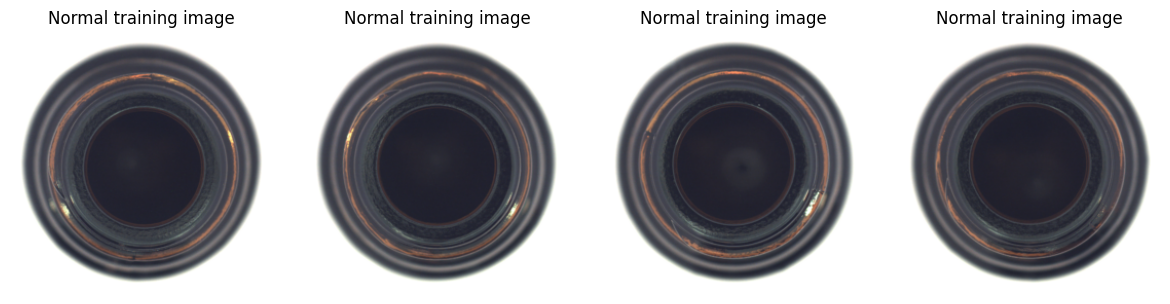

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, idx in zip(axes, np.linspace(0, len(train_dataset)-1, 4, dtype=int)):
    img = train_dataset[idx].permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.axis("off")
    ax.set_title("Normal training image")
plt.tight_layout()
plt.show()


## 6. Define the convolutional autoencoder

The encoder uses four stride-2 convolutional layers to reduce the spatial resolution:

`256×256×3 → 128×128×32 → 64×64×64 → 32×32×128 → 16×16×256`

The decoder mirrors this using transposed convolutions. The output is a reconstructed RGB image of size `256×256×3`.

The final sigmoid activation matches the input pixel range `[0, 1]`.


In [ ]:
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstruction = self.decoder(latent)
        return reconstruction


model = ConvAutoencoder().to(DEVICE)

# Verify tensor dimensions.
dummy = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE).to(DEVICE)
with torch.no_grad():
    reconstructed = model(dummy)
print("Input shape:         ", tuple(dummy.shape))
print("Reconstruction shape:", tuple(reconstructed.shape))
print("Number of parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
assert reconstructed.shape == dummy.shape


Input shape:          (2, 3, 256, 256)
Reconstruction shape: (2, 3, 256, 256)
Number of parameters: 1079715


## 7. Train the CAE

The model minimizes mean squared reconstruction error on normal images only. Validation loss is calculated on held-out normal images. The best model (lowest validation loss) is saved.

In [ ]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

best_val_loss = float("inf")
best_state = None
train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    running_train_loss = 0.0

    for images in train_loader:
        images = images.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, images)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)

    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            outputs = model(images)
            loss = criterion(outputs, images)
            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_dataset)

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, MODEL_DIR / f"{CATEGORY}_cae_best.pth")

    print(f"Epoch [{epoch+1:03d}/{EPOCHS}] "
          f"Train Loss: {epoch_train_loss:.6f} | "
          f"Val Loss: {epoch_val_loss:.6f}")

# Restore best validation-loss checkpoint.
model.load_state_dict(best_state)
print("Best validation loss:", best_val_loss)


Epoch [001/100] Train Loss: 0.143174 | Val Loss: 0.132970
Epoch [002/100] Train Loss: 0.111819 | Val Loss: 0.120902
Epoch [003/100] Train Loss: 0.094881 | Val Loss: 0.098146
Epoch [004/100] Train Loss: 0.083796 | Val Loss: 0.082429
Epoch [005/100] Train Loss: 0.074650 | Val Loss: 0.072594
Epoch [006/100] Train Loss: 0.066682 | Val Loss: 0.064020
Epoch [007/100] Train Loss: 0.059612 | Val Loss: 0.056409
Epoch [008/100] Train Loss: 0.053185 | Val Loss: 0.049957
Epoch [009/100] Train Loss: 0.047387 | Val Loss: 0.044230
Epoch [010/100] Train Loss: 0.042104 | Val Loss: 0.039101
Epoch [011/100] Train Loss: 0.037393 | Val Loss: 0.034662
Epoch [012/100] Train Loss: 0.033262 | Val Loss: 0.030834
Epoch [013/100] Train Loss: 0.029693 | Val Loss: 0.027640
Epoch [014/100] Train Loss: 0.026605 | Val Loss: 0.025114
Epoch [015/100] Train Loss: 0.023926 | Val Loss: 0.022727
Epoch [016/100] Train Loss: 0.021589 | Val Loss: 0.020567
Epoch [017/100] Train Loss: 0.019520 | Val Loss: 0.018612
Epoch [018/100

## 8. Plot training and validation loss

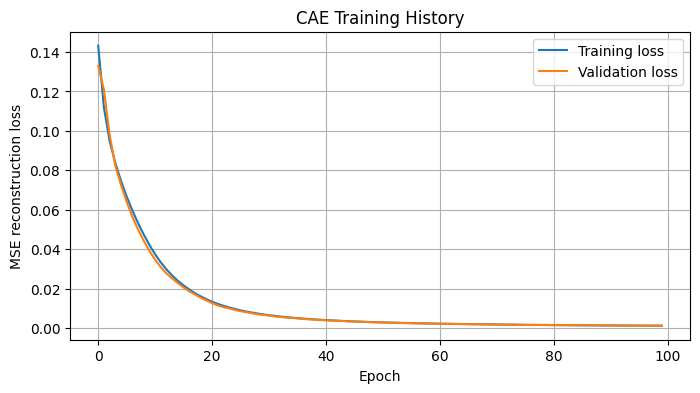

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE reconstruction loss")
plt.title("CAE Training History")
plt.legend()
plt.grid(True)
plt.show()


## 9. Calculate anomaly maps and image-level scores

For each image, calculate the mean squared difference across RGB channels at each pixel:

`anomaly_map[y, x] = mean_channel((input - reconstruction)²)`

The image-level score is the mean of the largest 1% of pixel errors. This top-percentile score can be more sensitive to small localized defects than the mean over the entire image. It is a design choice to evaluate, not a guaranteed optimal score.


In [ ]:
@torch.no_grad()
def get_reconstruction_errors(model, loader, is_test=False):
    model.eval()

    all_scores = []
    all_maps = []
    all_masks = []
    all_labels = []
    all_paths = []
    all_types = []

    for batch in loader:

        if is_test:
            images, masks, labels, paths, defect_types = batch
        else:
            images = batch

        images = images.to(DEVICE, non_blocking=True)
        reconstructions = model(images)

        # Calculate pixel-wise reconstruction error
        error_maps = torch.mean(
            (images - reconstructions) ** 2,
            dim=1
        )

        # Calculate image-level anomaly score
        flat = error_maps.flatten(start_dim=1)

        k = max(1, int(flat.shape[1] * TOP_FRACTION))

        image_scores = torch.topk(
            flat, k=k, dim=1
        ).values.mean(dim=1)

        all_scores.extend(image_scores.cpu().numpy().tolist())
        all_maps.extend(error_maps.cpu().numpy())

        if is_test:
            all_masks.extend(masks.squeeze(1).numpy())
            all_labels.extend(labels.numpy().tolist())
            all_paths.extend(list(paths))
            all_types.extend(list(defect_types))

    return (
        np.asarray(all_scores),
        np.asarray(all_maps),
        np.asarray(all_masks) if is_test else None,
        np.asarray(all_labels) if is_test else None,
        all_paths,
        all_types
    )


# ==========================================
# 1. Calibrate threshold using normal images
# ==========================================

val_scores, _, _, _, _, _ = get_reconstruction_errors(
    model, val_loader, is_test=False
)

threshold = float(
    np.percentile(val_scores, NORMAL_THRESHOLD_PERCENTILE)
)

print(
    f"Image-level threshold "
    f"({NORMAL_THRESHOLD_PERCENTILE}th percentile): {threshold:.8f}"
)


# ==========================================
# 2. Evaluate using test images
# ==========================================

test_scores, test_maps, test_masks, test_labels, test_paths, test_types = (
    get_reconstruction_errors(model, test_loader, is_test=True)
)

print("Test images:", len(test_scores))
print("Normal test images:", int((test_labels == 0).sum()))
print("Anomalous test images:", int((test_labels == 1).sum()))



Image-level threshold (99.0th percentile): 0.02852837
Test images: 83
Normal test images: 20
Anomalous test images: 63


## 10. Image-level evaluation

Confusion matrix (rows=true, columns=predicted):
[[19  1]
 [33 30]]

Classification report:
              precision    recall  f1-score   support

      normal       0.37      0.95      0.53        20
   anomalous       0.97      0.48      0.64        63

    accuracy                           0.59        83
   macro avg       0.67      0.71      0.58        83
weighted avg       0.82      0.59      0.61        83

Image-level AUROC: 0.7198


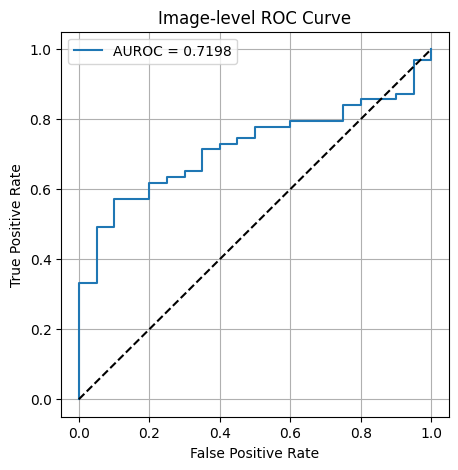

In [ ]:
test_predictions = (test_scores > threshold).astype(int)

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(test_labels, test_predictions, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(test_labels, test_predictions, target_names=["normal", "anomalous"],
                            zero_division=0))

if len(np.unique(test_labels)) == 2:
    image_auc = roc_auc_score(test_labels, test_scores)
    fpr, tpr, _ = roc_curve(test_labels, test_scores)
    print(f"Image-level AUROC: {image_auc:.4f}")

    plt.figure(figsize=(5, 5))
    plt.plot(fpr, tpr, label=f"AUROC = {image_auc:.4f}")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Image-level ROC Curve")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("Image AUROC cannot be calculated because the test set has only one class.")


## 11. Pixel-level evaluation

Pixel AUROC compares the continuous anomaly map with the binary ground-truth masks. It evaluates localization without choosing a pixel threshold. This calculation flattens all test pixels; it may take some time and memory.

In [ ]:
# Flatten pixel maps and masks for pixel-level AUROC.
pixel_scores = test_maps.reshape(-1)
pixel_targets = test_masks.reshape(-1).astype(np.uint8)

if len(np.unique(pixel_targets)) == 2:
    pixel_auc = roc_auc_score(pixel_targets, pixel_scores)
    print(f"Pixel-level AUROC: {pixel_auc:.4f}")
else:
    pixel_auc = None
    print("Pixel AUROC cannot be calculated: ground-truth pixels contain only one class.")


Pixel-level AUROC: 0.4797


## 12. Visualize original, reconstruction, anomaly map and ground truth

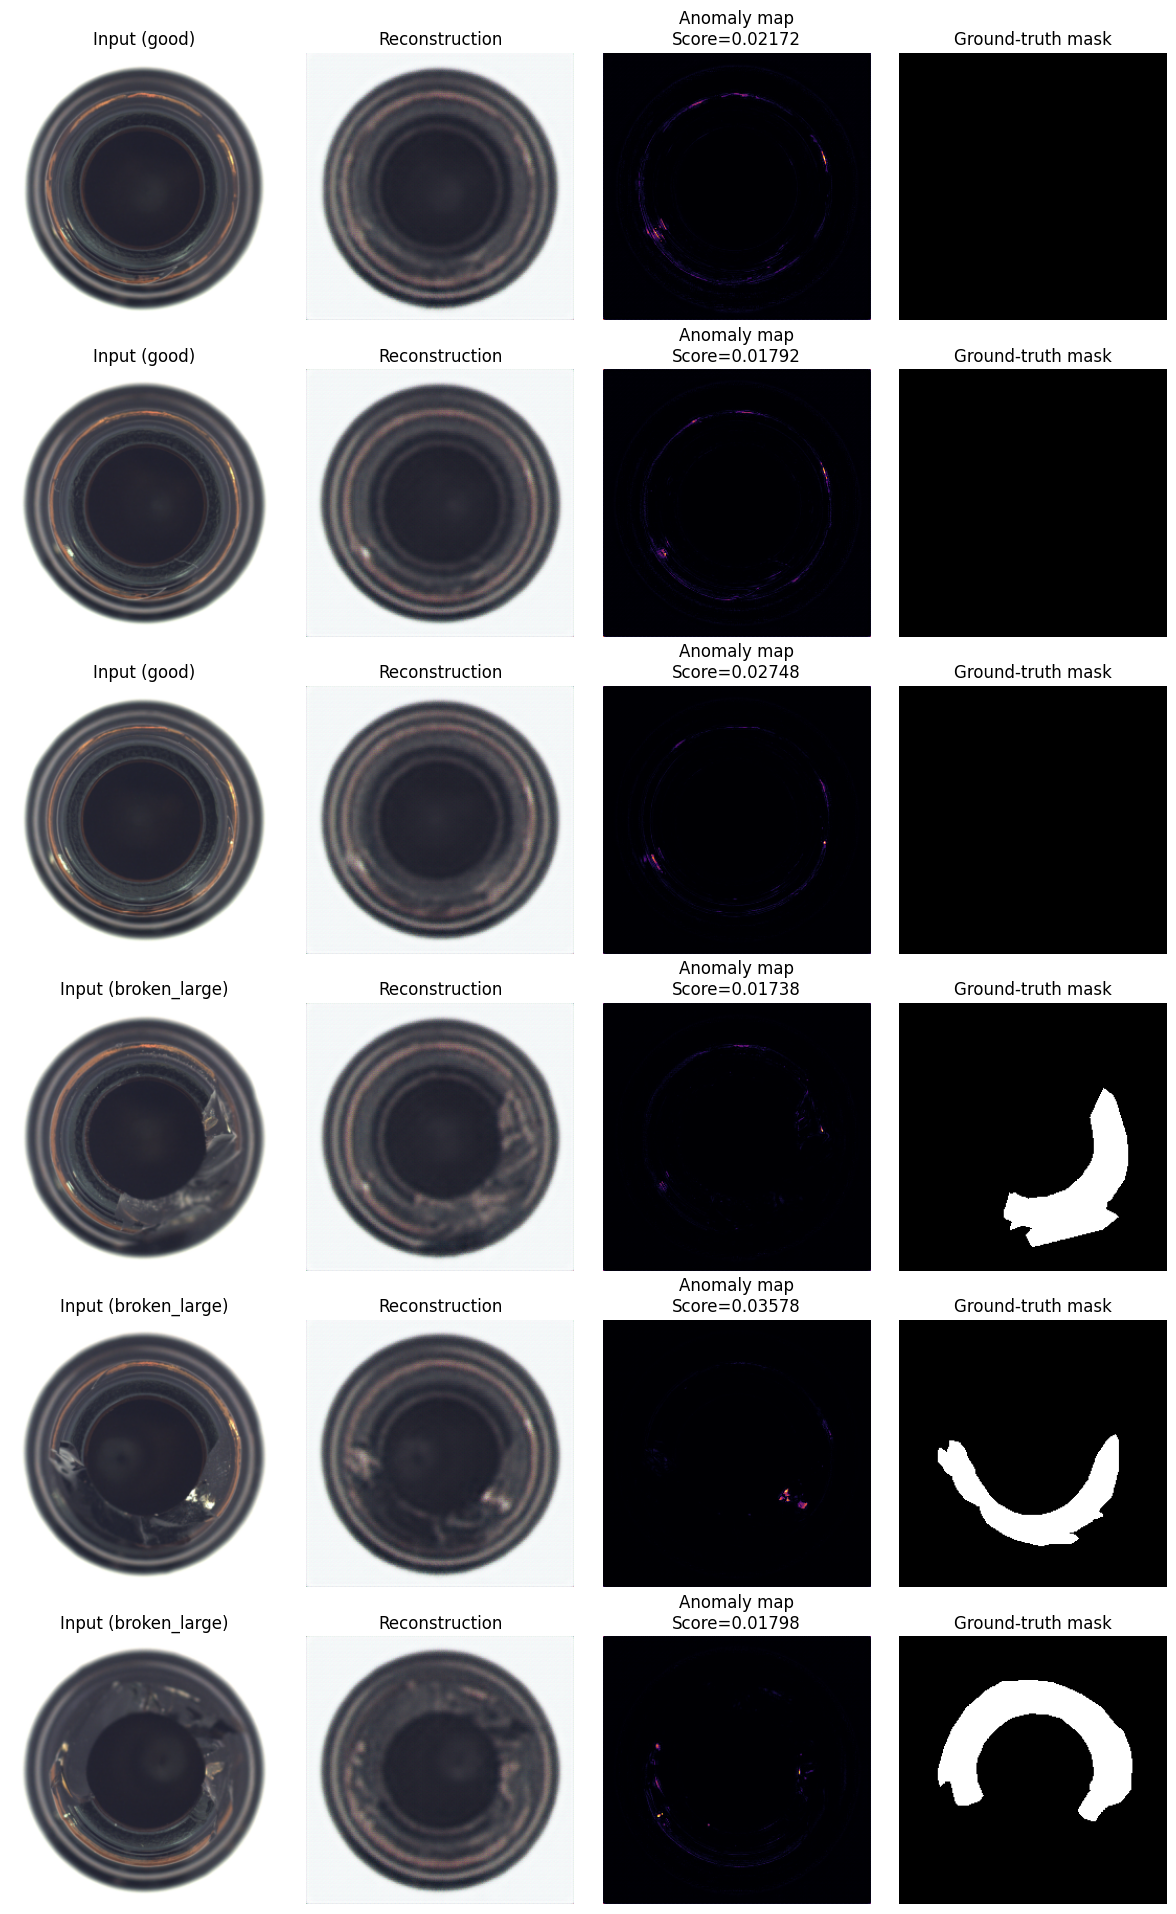

In [ ]:
@torch.no_grad()
def show_test_examples(model, dataset, scores, maps, masks, labels, paths, n=5):
    model.eval()
    # Prefer a mixture of normal and anomalous samples.
    normal_idx = np.where(labels == 0)[0]
    anomaly_idx = np.where(labels == 1)[0]
    chosen = list(normal_idx[:max(1, n // 2)]) + list(anomaly_idx[:max(1, n - n // 2)])
    chosen = chosen[:n]

    fig, axes = plt.subplots(len(chosen), 4, figsize=(12, 3.2 * len(chosen)))
    if len(chosen) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(chosen):
        image, mask, label, path, defect_type = dataset[idx]
        reconstruction = model(image.unsqueeze(0).to(DEVICE)).squeeze(0).cpu()
        original = image.permute(1, 2, 0).numpy()
        reconstructed = reconstruction.permute(1, 2, 0).numpy()

        axes[row, 0].imshow(original)
        axes[row, 0].set_title(f"Input ({defect_type})")
        axes[row, 1].imshow(reconstructed)
        axes[row, 1].set_title("Reconstruction")
        axes[row, 2].imshow(maps[idx], cmap="inferno")
        axes[row, 2].set_title(f"Anomaly map\nScore={scores[idx]:.5f}")
        axes[row, 3].imshow(masks[idx], cmap="gray", vmin=0, vmax=1)
        axes[row, 3].set_title("Ground-truth mask")

        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


show_test_examples(model, test_dataset, test_scores, test_maps,
                   test_masks, test_labels, test_paths, n=6)


## 13. Save model and experiment information

In [ ]:
checkpoint_path = MODEL_DIR / f"{CATEGORY}_cae_final.pth"
torch.save({
    "category": CATEGORY,
    "model_state_dict": model.state_dict(),
    "image_size": IMAGE_SIZE,
    "threshold": threshold,
    "threshold_percentile": NORMAL_THRESHOLD_PERCENTILE,
    "top_fraction": TOP_FRACTION,
    "train_losses": train_losses,
    "val_losses": val_losses,
}, checkpoint_path)

print("Saved checkpoint:", checkpoint_path)


Saved checkpoint: /content/drive/MyDrive/CAE_MVTec_outputs/bottle_cae_final.pth


## 14. Test the model on a single image

Set `IMAGE_PATH` to an image file. The code displays its reconstruction, anomaly map, image-level score and threshold-based prediction.


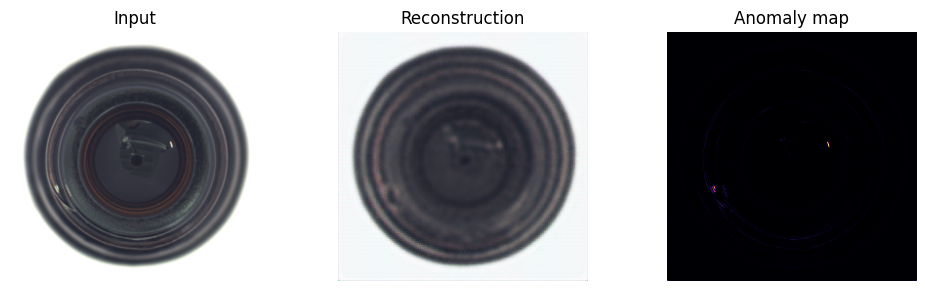

Anomaly score: 0.01737213
Threshold:     0.02852837
Prediction:    NORMAL


In [ ]:
IMAGE_PATH = "/content/drive/MyDrive/MvTec/bottle/test/contamination/010.png"  # Example: "/content/drive/MyDrive/MvTec/bottle/test/broken_large/018.png"

if IMAGE_PATH is not None:
    transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor()
    ])
    image = Image.open(IMAGE_PATH).convert("RGB")
    x = transform(image).unsqueeze(0).to(DEVICE)

    model.eval()
    with torch.no_grad():
        recon = model(x)
        error_map = torch.mean((x - recon) ** 2, dim=1)[0]
        flat = error_map.flatten()
        k = max(1, int(flat.numel() * TOP_FRACTION))
        score = torch.topk(flat, k=k).values.mean().item()

    prediction = "ANOMALOUS" if score > threshold else "NORMAL"

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    axes[0].imshow(x[0].cpu().permute(1, 2, 0))
    axes[0].set_title("Input")
    axes[1].imshow(recon[0].cpu().permute(1, 2, 0))
    axes[1].set_title("Reconstruction")
    axes[2].imshow(error_map.cpu(), cmap="inferno")
    axes[2].set_title("Anomaly map")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    print(f"Anomaly score: {score:.8f}")
    print(f"Threshold:     {threshold:.8f}")
    print(f"Prediction:    {prediction}")
else:
    print("Set IMAGE_PATH to run single-image inference.")


## 15. Notes and limitations

1. **Training data:** Only normal images from `train/good` are used to optimize the CAE.
2. **Validation:** The threshold is calibrated from held-out normal images. With a small validation set, a 99th-percentile threshold can be unstable; report this limitation and consider comparing 95th, 97.5th and 99th percentiles.
3. **Test set:** Test labels and masks are used only for final evaluation and visualization, not training or threshold selection.
4. **Reconstruction limitation:** A CAE may reconstruct some defects well, so reconstruction error is not always a reliable indicator.
5. **Image resizing:** Resizing to 256×256 can remove fine details. You can experiment with higher resolution if GPU memory permits.
6. **Data augmentation:** Only horizontal flipping is enabled by default. Check that transformations are appropriate for the chosen product category.
7. **Reproducibility:** Record the category, random seed, image size, epochs, batch size, learning rate, score definition and threshold in your report.

### Suggested next experiments
- Compare latent capacity by changing the encoder channel sizes.
- Compare mean pixel error against top-1% pixel error as the image-level score.
- Compare MSE with an SSIM-based reconstruction objective.
- Repeat the experiment on `screw` or `capsule` and compare image-level and pixel-level AUROC.
